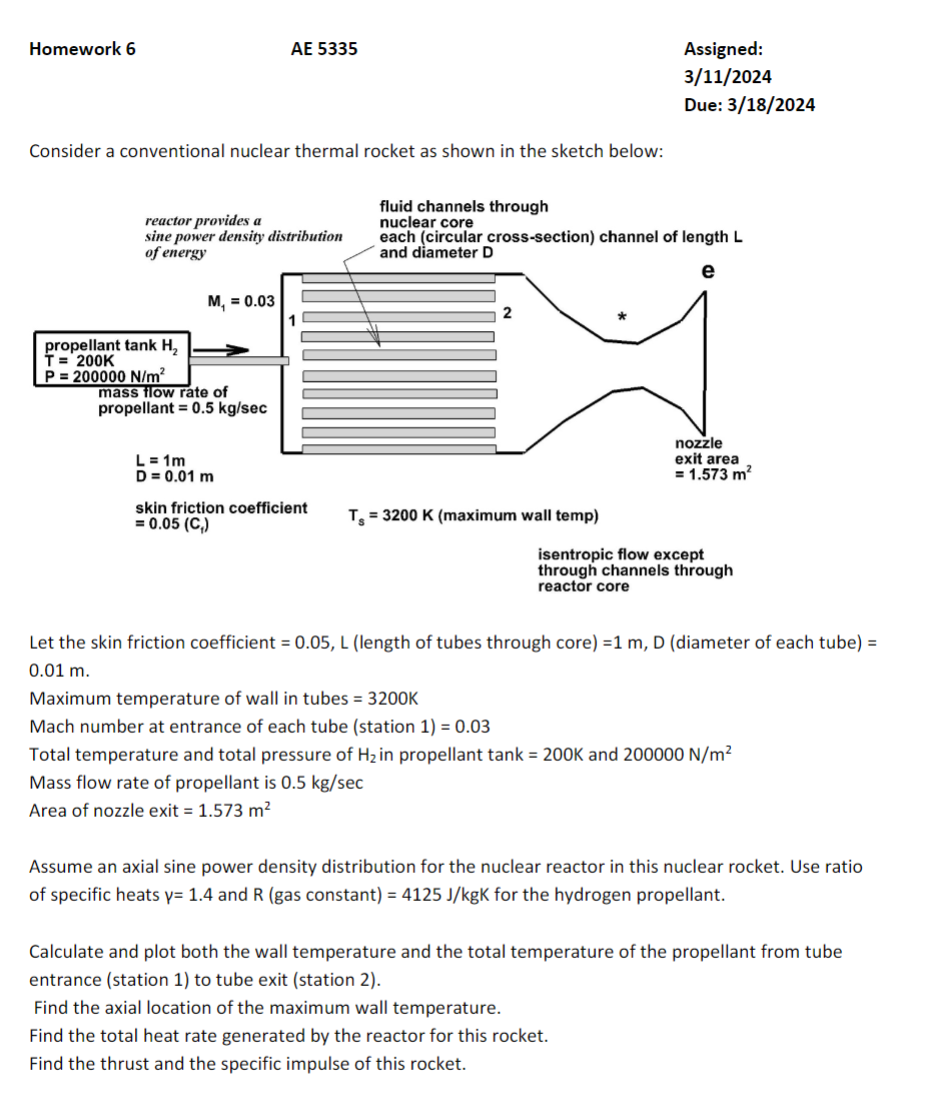

In [13]:
import numpy as np
import scipy
fsolve = scipy.optimize.fsolve
import matplotlib.pyplot as plt

# Given

In [14]:
cf = 0.05
L = 1           # m
D = 0.01        # m
Ts = 3200     # K
M1 = 0.03
Tt_h2 = 200     # K
Pt_h2 = 200000  # Pa
m_dot_p = 0.5   # kg/s
Ae = 1.573      # m^2

gamma = 1.4
Rh2 = 4125        # J/kgK

In [8]:
R =  (np.pi * D)/( cf * L )
R

0.6283185307179586

In [9]:
Tt1 = Tt_h2
Pt1 = Pt_h2

In [22]:
x_L_maxT = 1 + 1/np.pi * np.arctan(-R/2)
x_L_maxT

0.9031078083860451

In [21]:
func = lambda dTm: Tt1 - Ts + 2/R * dTm * (1+np.sqrt(1+(R/2)**2))
dTm = fsolve(func,200)
dTm

array([460.1522144])

In [24]:
Tt2 = 4/R * dTm + Tt1
Tt2

array([3129.41997986])

In [28]:
cp = (gamma/(gamma-1))*Rh2

Q_dot = m_dot_p * cp * (Tt2 - Tt1)

print(cp)
print(Q_dot/1000/1000)

14437.500000000002
[21.14675048]


In [34]:
func2 = lambda M2: M2/M1 * (1+gamma*M1**2*(1-cf*L/D))/(1+gamma*M2**2*(1+cf*L/D)) * ((1+(gamma-1)/2*M2**2)/(1+(gamma-1)/2*M1**2))**.5 - np.sqrt(Tt2/Tt1)
M2 = fsolve(func2,.01)
M2

array([0.13813702])

In [35]:
P2_P1 = (1+gamma*M1**2*(1-cf*L/D))/(1+gamma*M2**2*(1+cf*L/D))
P2_P1

array([0.85751166])

In [38]:
Pt2_Pt1 = P2_P1*((1+(gamma-1)/2*M2**2)/(1+(gamma-1)/2*M1**2))**(gamma/(gamma-1))
Pt2_Pt1

array([0.86847317])

In [40]:
Pt2 = Pt2_Pt1 * Pt1
Pc = Pt2
Pc/1000

array([173.69463373])